Epoch 1/20, Loss: 88.96572875976562
Epoch 2/20, Loss: 84.84974670410156
Epoch 3/20, Loss: 81.51372528076172
Epoch 4/20, Loss: 78.71942901611328
Epoch 5/20, Loss: 76.3725357055664
Epoch 6/20, Loss: 74.71003723144531
Epoch 7/20, Loss: 73.30412292480469
Epoch 8/20, Loss: 72.33534240722656
Epoch 9/20, Loss: 71.45304107666016
Epoch 10/20, Loss: 70.87928009033203
Epoch 11/20, Loss: 70.39633178710938
Epoch 12/20, Loss: 69.98876190185547
Epoch 13/20, Loss: 69.60958862304688
Epoch 14/20, Loss: 69.4093246459961
Epoch 15/20, Loss: 69.22786712646484
Epoch 16/20, Loss: 69.04573059082031
Epoch 17/20, Loss: 68.87174987792969
Epoch 18/20, Loss: 68.78976440429688
Epoch 19/20, Loss: 68.60828399658203
Epoch 20/20, Loss: 68.52909088134766


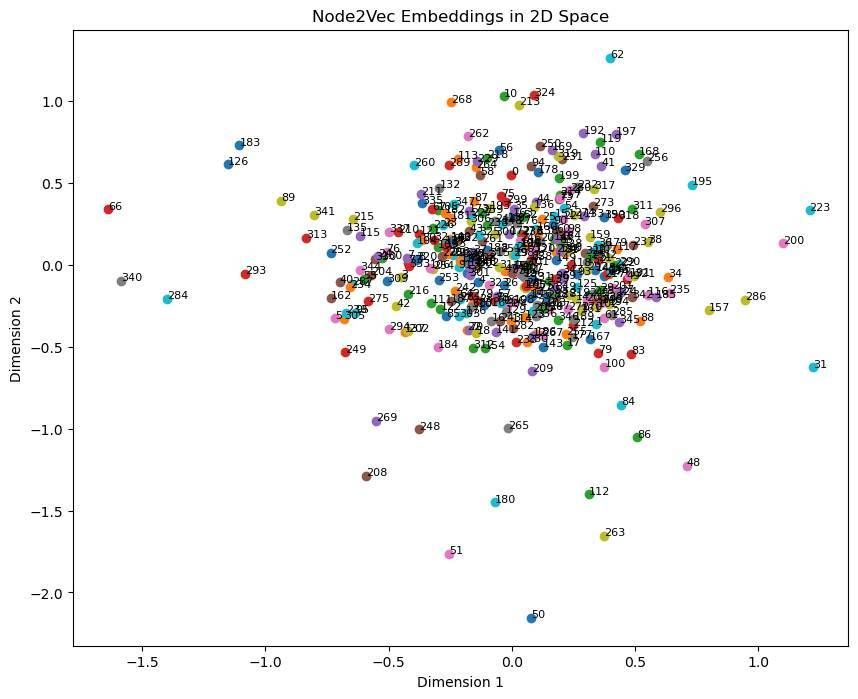

In [8]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.optim as optim

edges_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Node2Vec/edges.txt'
labels_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Node2Vec/Cluster_labels.txt'
data = pd.read_csv(edges_path, sep=" ", header=None, names=['source', 'target'])
labels = pd.read_csv(labels_path, sep=" : ", header=None, names=['node', 'cluster'], engine='python')
labels['node'] = labels['node'].astype(int)
labels['cluster'] = labels['cluster'].astype(int)
G = nx.Graph()
G.add_edges_from(data.values)

# All Parameters for Node2Vec that we have
embedding_dim = 2
walk_length = 10 
num_walks_per_node = 10
p = 0.5
q = 2
num_epochs = 20  
learning_rate = 0.08 
negative_samples = 10

node_embeddings = torch.randn((G.number_of_nodes(), embedding_dim), requires_grad=True)
optimizer = optim.Adam([node_embeddings], lr=learning_rate)

def generate_random_walks(G, walk_length, num_walks_per_node):
    walks = []
    nodes = list(G.nodes())
    for _ in range(num_walks_per_node):
        for node in nodes:
            walk = [node]
            for _ in range(walk_length - 1):
                neighbors = list(G.neighbors(walk[-1]))
                if neighbors:
                    walk.append(np.random.choice(neighbors))
                else:
                    break
            walks.append(walk)
    return walks

def negative_sampling(G, node, num_samples):
    negatives = []
    while len(negatives) < num_samples:
        sample = np.random.choice(list(G.nodes()))
        if sample != node and not G.has_edge(node, sample):
            negatives.append(sample)
    return negatives

for epoch in range(num_epochs):
    random_walks = generate_random_walks(G, walk_length, num_walks_per_node)
    optimizer.zero_grad()
    loss = 0
    for walk in random_walks:
        for i in range(len(walk) - 1):
            u = walk[i]
            v = walk[i + 1]
            pos_score = torch.dot(node_embeddings[u], node_embeddings[v])
            pos_loss = -torch.log(torch.sigmoid(pos_score))
            neg_nodes = negative_sampling(G, u, negative_samples)
            neg_loss = 0
            for neg in neg_nodes:
                neg_score = torch.dot(node_embeddings[u], node_embeddings[neg])
                neg_loss += -torch.log(torch.sigmoid(-neg_score))
            loss += pos_loss + neg_loss
    loss /= len(random_walks)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {loss.item()}")

# Visualizing the embeddings
node_embeddings = node_embeddings.detach().numpy()
plt.figure(figsize=(10, 8))
for i, node in enumerate(G.nodes()):
    plt.scatter(node_embeddings[i, 0], node_embeddings[i, 1], label=str(node))
    plt.text(node_embeddings[i, 0], node_embeddings[i, 1], str(node), fontsize=8)
plt.title('Node2Vec Embeddings in 2D Space')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.show()

Testing parameters: walk_length=5, num_walks_per_node=3, p=0.5, q=0.5
Testing parameters: walk_length=5, num_walks_per_node=3, p=0.5, q=1
Testing parameters: walk_length=5, num_walks_per_node=3, p=0.5, q=2
Testing parameters: walk_length=5, num_walks_per_node=3, p=1, q=0.5
Testing parameters: walk_length=5, num_walks_per_node=3, p=1, q=1
Testing parameters: walk_length=5, num_walks_per_node=3, p=1, q=2
Testing parameters: walk_length=5, num_walks_per_node=3, p=2, q=0.5
Testing parameters: walk_length=5, num_walks_per_node=3, p=2, q=1
Testing parameters: walk_length=5, num_walks_per_node=3, p=2, q=2
Testing parameters: walk_length=5, num_walks_per_node=5, p=0.5, q=0.5
Testing parameters: walk_length=5, num_walks_per_node=5, p=0.5, q=1
Testing parameters: walk_length=5, num_walks_per_node=5, p=0.5, q=2
Testing parameters: walk_length=5, num_walks_per_node=5, p=1, q=0.5
Testing parameters: walk_length=5, num_walks_per_node=5, p=1, q=1
Testing parameters: walk_length=5, num_walks_per_node=

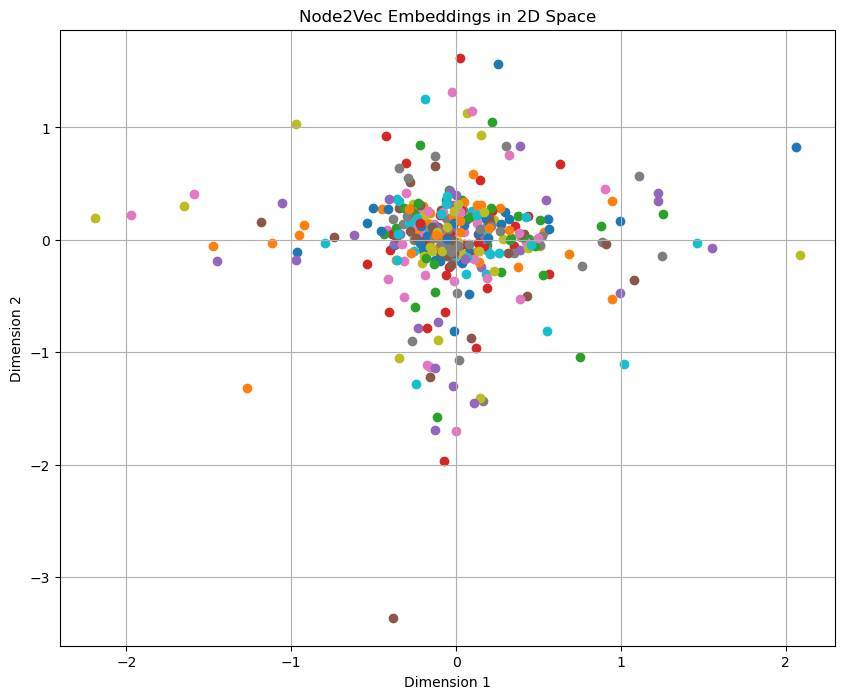

In [9]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.optim as optim
from itertools import product

edges_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Node2Vec/edges.txt'
labels_path = 'F:/Aidin/Universities/Amirkabir (Master)/Lessons/Term 2/Analysis of Complex Networks/Assignments/HW2/Answer/Dataset/Node2Vec/Cluster_labels.txt'
data = pd.read_csv(edges_path, sep=" ", header=None, names=['source', 'target'])
labels = pd.read_csv(labels_path, sep=" : ", header=None, names=['node', 'cluster'], engine='python')
labels['node'] = labels['node'].astype(int)
labels['cluster'] = labels['cluster'].astype(int)
G = nx.Graph()
G.add_edges_from(data.values)

# All Parameters for Node2Vec that we have
embedding_dim = 2
num_epochs = 15 
learning_rate = 0.07  
negative_samples = 10

# Hyperparameter grid search
walk_lengths = [5, 10]
num_walks_per_nodes = [3, 5]
p_values = [0.5, 1, 2]
q_values = [0.5, 1, 2]
best_loss = float('inf')
best_params = {}

def generate_random_walks(G, walk_length, num_walks_per_node):
    walks = []
    nodes = list(G.nodes())
    for _ in range(num_walks_per_node):
        for node in nodes:
            walk = [node]
            for _ in range(walk_length - 1):
                neighbors = list(G.neighbors(walk[-1]))
                if neighbors:
                    walk.append(np.random.choice(neighbors))
                else:
                    break
            walks.append(walk)
    return walks

def negative_sampling(G, node, num_samples):
    negatives = []
    while len(negatives) < num_samples:
        sample = np.random.choice(list(G.nodes()))
        if sample != node and not G.has_edge(node, sample):
            negatives.append(sample)
    return negatives

for walk_length, num_walks_per_node, p, q in product(walk_lengths, num_walks_per_nodes, p_values, q_values):
    print(f"Testing parameters: walk_length={walk_length}, num_walks_per_node={num_walks_per_node}, p={p}, q={q}")
    node_embeddings = torch.randn((G.number_of_nodes(), embedding_dim), requires_grad=True)
    optimizer = optim.Adam([node_embeddings], lr=learning_rate)
    for epoch in range(num_epochs):
        random_walks = generate_random_walks(G, walk_length, num_walks_per_node)
        optimizer.zero_grad()
        loss = 0
        for walk in random_walks:
            for i in range(len(walk) - 1):
                u = walk[i]
                v = walk[i + 1]
                pos_score = torch.dot(node_embeddings[u], node_embeddings[v])
                pos_loss = -torch.log(torch.sigmoid(pos_score))
                neg_nodes = negative_sampling(G, u, negative_samples)
                neg_loss = 0
                for neg in neg_nodes:
                    neg_score = torch.dot(node_embeddings[u], node_embeddings[neg])
                    neg_loss += -torch.log(torch.sigmoid(-neg_score))
                loss += pos_loss + neg_loss
        loss /= len(random_walks)
        loss.backward()
        optimizer.step()
    if loss.item() < best_loss:
        best_loss = loss.item()
        best_params = {
            'walk_length': walk_length,
            'num_walks_per_node': num_walks_per_node,
            'p': p,
            'q': q
        }

print(f"Best parameters: {best_params}, Best loss: {best_loss}")
random_walks = generate_random_walks(G, best_params['walk_length'], best_params['num_walks_per_node'])
node_embeddings = node_embeddings.detach().numpy()
plt.figure(figsize=(10, 8))
for i in range(len(node_embeddings)):
    plt.scatter(node_embeddings[i, 0], node_embeddings[i, 1])
plt.title('Node2Vec Embeddings in 2D Space')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.grid(True)
plt.show()